In [1]:
#ДЗ 
# 1. Для изображения sar_3.jpg найти наиболее протяженный участок
# (выделить линии при помощи преобразования Хафа)
# 2. Для изображения sar_3.jpg провести исследование алгоритмов бинаризации, выделить участок дорожной полосы.

In [2]:
## Импорт библиотек

import numpy as np
import cv2
import matplotlib.pyplot as plt

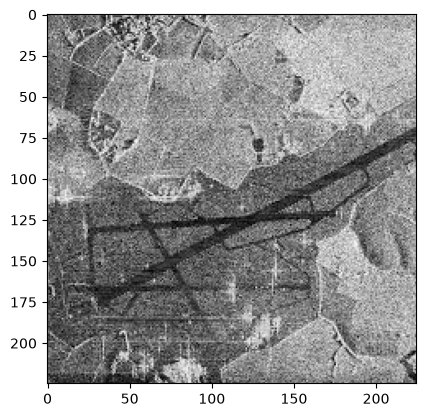

In [3]:
image = cv2.imread('sar_3.jpg')
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image_rgb)
plt.show()

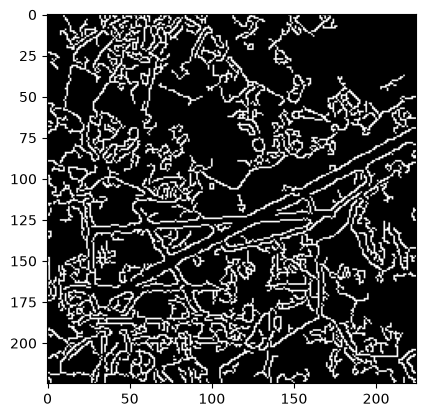

In [4]:
## Выделение границ изображения

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

blurred = cv2.GaussianBlur(gray, (5, 5), 0)

edges = cv2.Canny(blurred, 50, 150)

plt.imshow(edges, cmap='gray')
plt.show()


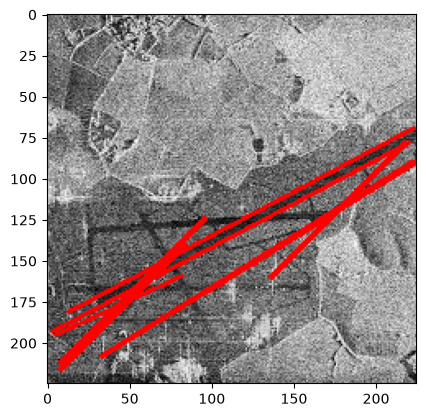

Найдено линий: 8


In [5]:
## Поиск линий преобразованием Хафа

lines = cv2.HoughLinesP(
    edges,
    rho=1,
    theta=np.pi / 180,
    threshold=45,
    minLineLength=75,
    maxLineGap=15
)

result = image_rgb.copy()
selected_lines = []

if lines is not None:
    for x1, y1, x2, y2 in lines.reshape(-1, 4):
        length = np.hypot(x2 - x1, y2 - y1)

        angle = np.degrees(np.arctan2(y2 - y1, x2 - x1))
        angle = (angle + 90) % 180 - 90

        middle_x = (x1 + x2) / 2
        middle_y = (y1 + y2) / 2

        road_y = 205 - 0.55 * middle_x

        if (length >= 75
                and -50 <= angle <= -15
                and abs(middle_y - road_y) < 18):
            selected_lines.append((x1, y1, x2, y2))
            cv2.line(result, (x1, y1), (x2, y2), (255, 0, 0), 2)

plt.imshow(result)
plt.show()

print("Найдено линий:", len(selected_lines))


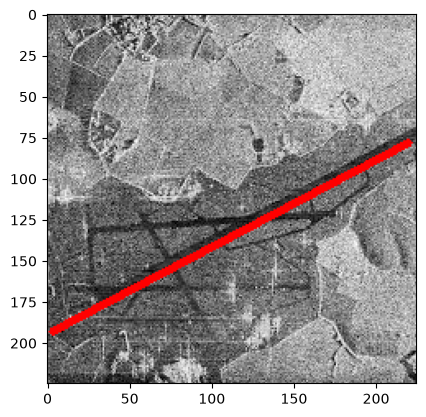

Длина самой длинной линии: 245.59 пикселей


In [6]:
## Поиск самой длинной линии

result_longest = image_rgb.copy()

longest_line = None
max_length = 0

for x1, y1, x2, y2 in selected_lines:
    length = np.hypot(x2 - x1, y2 - y1)

    if length > max_length:
        max_length = length
        longest_line = (x1, y1, x2, y2)

if longest_line is not None:
    x1, y1, x2, y2 = longest_line
    cv2.line(result_longest, (x1, y1), (x2, y2), (255, 0, 0), 3)

plt.imshow(result_longest)
plt.show()

print("Длина самой длинной линии:", round(max_length, 2), "пикселей")


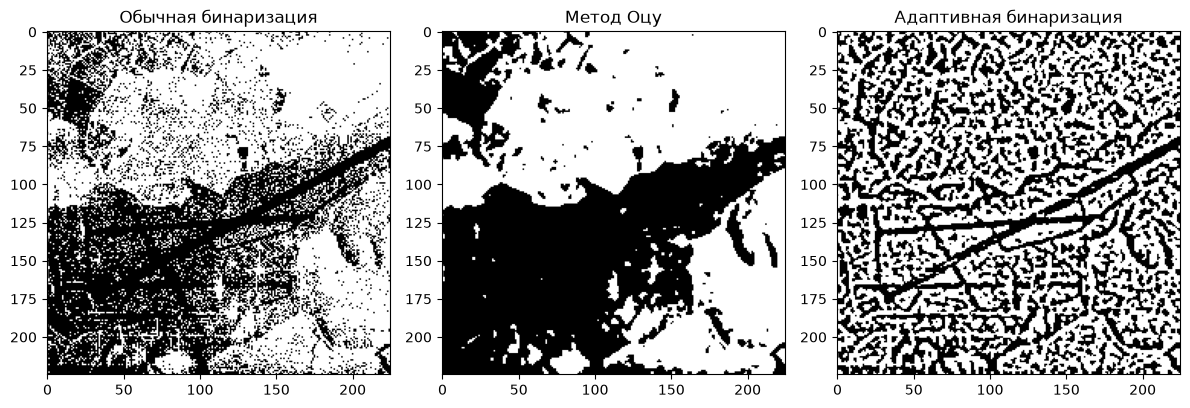

In [7]:
## Бинаризация изображения различными методами

_, binary = cv2.threshold(gray, 120, 255, cv2.THRESH_BINARY)

_, otsu = cv2.threshold(
    blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

adaptive = cv2.adaptiveThreshold(
    blurred, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY, 11, 2
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(binary, cmap='gray')
plt.title('Обычная бинаризация')

plt.subplot(1, 3, 2)
plt.imshow(otsu, cmap='gray')
plt.title('Метод Оцу')

plt.subplot(1, 3, 3)
plt.imshow(adaptive, cmap='gray')
plt.title('Адаптивная бинаризация')

plt.tight_layout()
plt.show()


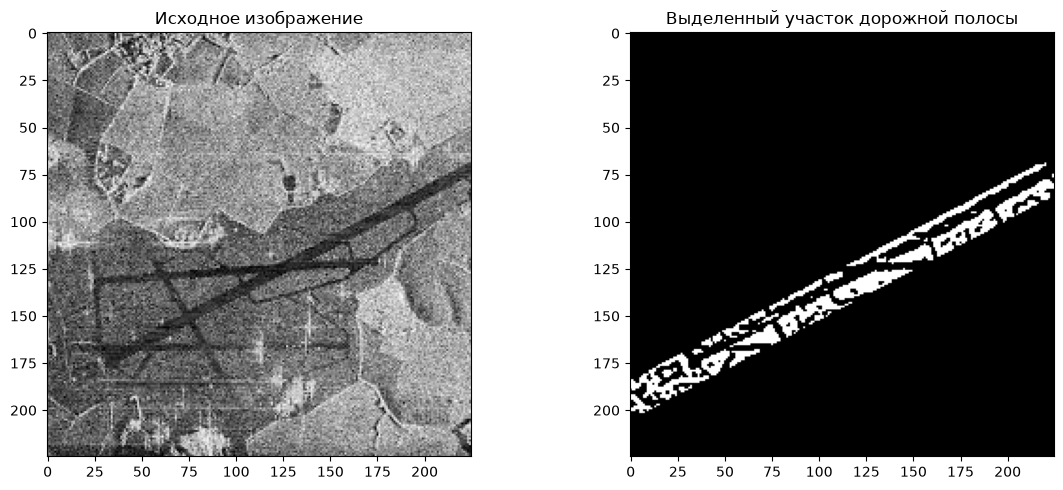

In [8]:
## Выделение участка дорожной полосы

road_mask = np.zeros_like(gray)

x1, y1, x2, y2 = longest_line

cv2.line(road_mask, (x1, y1), (x2, y2), 255, 18)

road_binary = cv2.bitwise_and(adaptive, road_mask)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title('Исходное изображение')

plt.subplot(1, 2, 2)
plt.imshow(road_binary, cmap='gray')
plt.title('Выделенный участок дорожной полосы')

plt.tight_layout()
plt.show()
